# Imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from cellpose import core, io, models, train

## Helper functions

In [2]:
def load_split(split_dir):
    """Load TIFF images and matching Cellpose *_seg.npy ground-truth masks."""
    image_paths = sorted(split_dir.glob("*.tif"))
    if not image_paths:
        raise FileNotFoundError(f"No .tif images found in {split_dir}")

    mask_paths = [split_dir / f"{image_path.stem}_seg.npy" for image_path in image_paths]
    missing_masks = [path for path in mask_paths if not path.is_file()]
    if missing_masks:
        raise FileNotFoundError(f"Missing ground-truth mask: {missing_masks[0]}")

    images = [io.imread(str(path)) for path in image_paths]
    labels = [np.load(path, allow_pickle=True).item()["masks"] for path in mask_paths]
    for image_path, image, label in zip(image_paths, images, labels):
        if image.shape[:2] != label.shape[:2]:
            raise ValueError(
                f"Image/mask shape mismatch for {image_path}: {image.shape} vs {label.shape}"
            )

    print(f"{split_dir.name}: loaded {len(images)} image/mask pairs")
    return images, labels, image_paths, mask_paths


def to_display(image):
    """Normalize a grayscale image for display."""
    image = np.asarray(image, dtype=np.float32)
    if image.ndim == 3 and image.shape[-1] == 1:
        image = image[..., 0]
    if image.ndim != 2:
        raise ValueError(f"Expected a 2D grayscale image, got shape {image.shape}")
    low, high = np.percentile(image, (1, 99))
    return np.clip((image - low) / (high - low + 1e-8), 0, 1)


def plot_predictions(images, predicted_masks, true_masks, image_paths):
    """Display each image beside its predicted mask and ground-truth mask."""
    n_images = len(images)
    if n_images == 0:
        raise ValueError("No images were provided for visualization")
    if not (n_images == len(predicted_masks) == len(true_masks) == len(image_paths)):
        raise ValueError("Images, predictions, labels, and paths must have equal lengths")

    fig, axes = plt.subplots(n_images, 3, figsize=(16, 4 * n_images), squeeze=False)
    titles = ("Input image", "Pretrained model prediction", "Ground truth")
    for row, (image, prediction, label, image_path) in enumerate(
        zip(images, predicted_masks, true_masks, image_paths)
    ):
        axes[row, 0].imshow(to_display(image), cmap="gray")
        axes[row, 0].set_ylabel(Path(image_path).name)
        axes[row, 1].imshow(prediction, cmap="nipy_spectral", interpolation="nearest")
        axes[row, 2].imshow(label, cmap="nipy_spectral", interpolation="nearest")
        for column, ax in enumerate(axes[row]):
            ax.set_xticks([])
            ax.set_yticks([])
            if row == 0:
                ax.set_title(titles[column])

    fig.tight_layout()
    plt.show()

## Load the prepared dataset

In [3]:
dataset_name = "A172_splits_n100_seed42"
data_dir_candidates = (Path("../data"), Path("cellpose/data"), Path("data"))
data_dir = next(
    (path for path in data_dir_candidates if (path / dataset_name).is_dir()),
    None,
)
if data_dir is None:
    raise FileNotFoundError(
        f"Could not find {dataset_name}; checked: {data_dir_candidates}"
    )
prepared_dir = data_dir / dataset_name

train_dir = prepared_dir / "train"
validation_dir = prepared_dir / "validation"
test_dir = prepared_dir / "test"

for split_dir in (train_dir, validation_dir, test_dir):
    if not split_dir.is_dir():
        raise FileNotFoundError(f"Prepared split directory not found: {split_dir.resolve()}")

print(f"Prepared dataset: {prepared_dir.resolve()}")

Prepared dataset: /storage/research/dsl_vibe_rs/trainings/2026_deep_learning_with_VIBE/cellpose/data/A172_splits_n100_seed42


In [4]:
train_data, train_labels, train_image_paths, train_mask_paths = load_split(train_dir)
validation_data, validation_labels, validation_image_paths, validation_mask_paths = load_split(validation_dir)
test_data, test_labels, test_image_paths, test_mask_paths = load_split(test_dir)

# These paired paths and arrays are ready for the training section below.
train_image_mask_paths = list(zip(train_image_paths, train_mask_paths))
validation_image_mask_paths = list(zip(validation_image_paths, validation_mask_paths))
test_image_mask_paths = list(zip(test_image_paths, test_mask_paths))

# print("Training image/mask paths:")
# for image_path, mask_path in train_image_mask_paths:
#     print(f"image: {image_path} | mask: {mask_path}")

train: loaded 80 image/mask pairs
validation: loaded 10 image/mask pairs
test: loaded 10 image/mask pairs


## Load the pretrained Cellpose-SAM model

In [5]:
io.logger_setup()
if not core.use_gpu():
    raise ImportError("No GPU access; use a VIBE instance with GPU support")

# Default pretrained model is cpsam_v2.
model = models.CellposeModel(gpu=True)
# Other available pretrained models can be selected here:
# model = models.CellposeModel(gpu=True, pretrained_model="cpdino")
# model = models.CellposeModel(gpu=True, pretrained_model="cpdino-vitb")

[GUI INFO] : WRITING LOG OUTPUT TO /storage/homefs/rl18y689/.cellpose/run.log

cellpose version: 	4.2.1.1 
platform:       	linux 
python version: 	3.13.15 
torch version:  	2.14.0+cu130
2026-10-26 11:05:16,712 [io INFO] WRITING LOG OUTPUT TO /storage/homefs/rl18y689/.cellpose/run.log
2026-10-26 11:05:16,712 [io INFO] 
cellpose version: 	4.2.1.1 
platform:       	linux 
python version: 	3.13.15 
torch version:  	2.14.0+cu130
2026-10-26 11:05:16,952 [core INFO] ** TORCH CUDA version installed and working. **
2026-10-26 11:05:16,953 [core INFO] ** TORCH CUDA version installed and working. **
2026-10-26 11:05:16,953 [core INFO] >>>> using GPU (CUDA)
2026-10-26 11:05:24,156 [models INFO] >>>> loading model /storage/homefs/rl18y689/.vibe/.cellpose/models/cpsam_v2


## Compare pretrained predictions with test ground truth

This is a baseline from the default pretrained model, before fine-tuning it on this dataset.

/opt/.pixi/envs/cellpose-gui-training/lib/python3.13/site-packages/cellpose/dynamics.py:541: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),


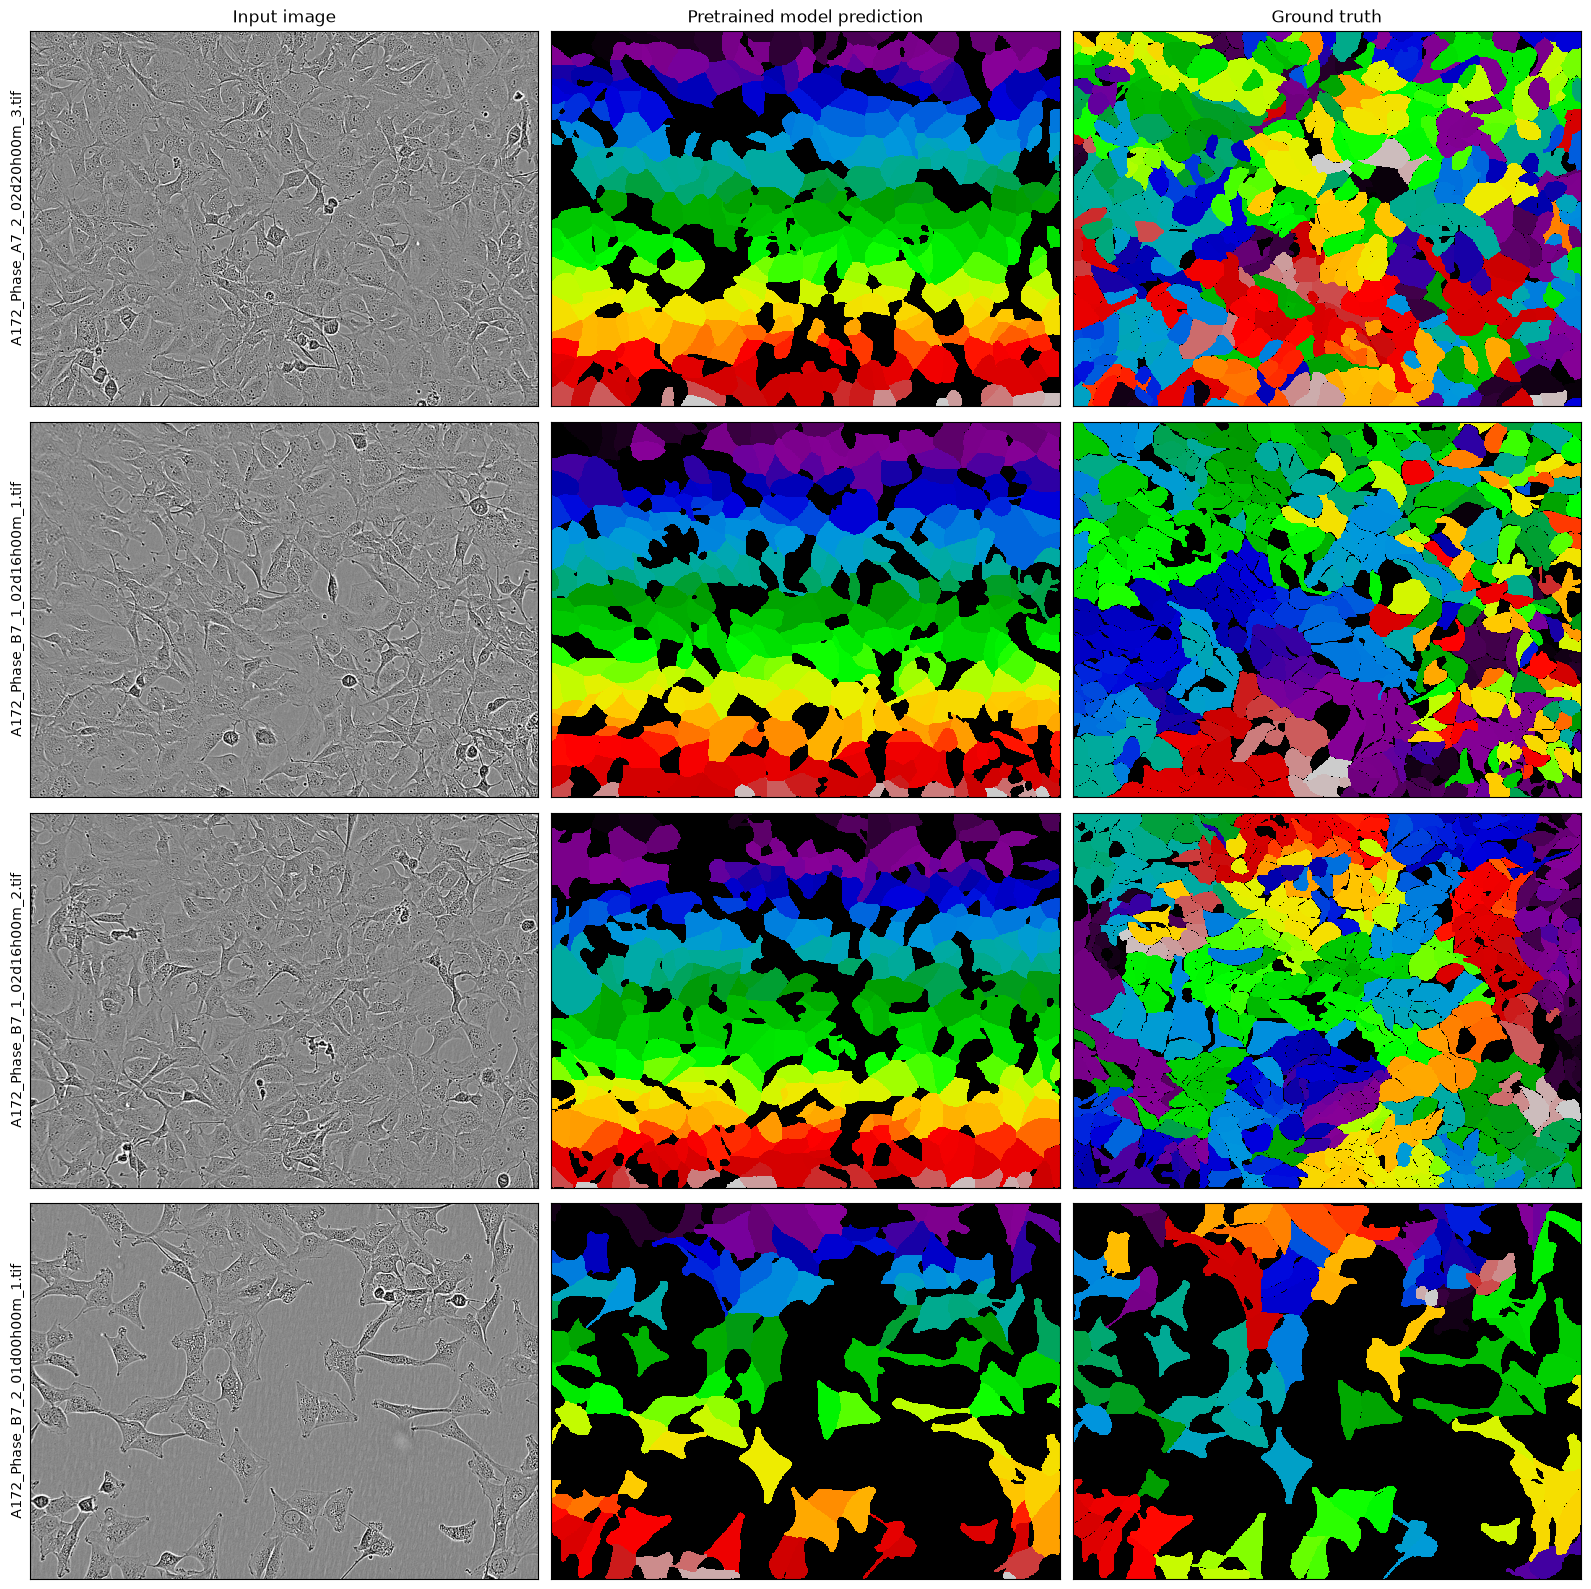

In [6]:
n_preview = min(4, len(test_data))
default_test_predictions = [model.eval(image)[0] for image in test_data[:n_preview]]

plot_predictions(
    test_data[:n_preview],
    default_test_predictions,
    test_labels[:n_preview],
    test_image_paths[:n_preview],
)

## Train the model

Fine-tune on `train_data` and `train_labels`. The test split is passed to Cellpose for evaluation during training, then used below to compare the default and fine-tuned models against ground truth.

In [7]:
n_epochs = 10
learning_rate = 1e-5
weight_decay = 0.1
batch_size = 5

model_name = f"{dataset_name}_cpsam_v2_finetuned_n_epochs{n_epochs}_b_size{batch_size}_w_decay{str(weight_decay)}_l_rate{str(learning_rate)}"

new_model_path, train_losses, test_losses = train.train_seg(
    model.net,
    train_data=train_data,
    train_labels=train_labels,
    test_data=test_data,
    test_labels=test_labels,
    batch_size=batch_size,
    n_epochs=n_epochs,
    learning_rate=learning_rate,
    weight_decay=weight_decay,
    # images sampled per epoch: all of them, at least 2
    nimg_per_epoch=max(2, len(train_data)),
    nimg_test_per_epoch=max(2, len(test_data)),
    model_name=model_name,
)
print(f"Fine-tuned model saved to {new_model_path}")

trained_model = models.CellposeModel(gpu=True, pretrained_model=new_model_path)

2026-10-26 11:05:27,826 [train INFO] >>> converting bfloat16 network to float32 for training
2026-10-26 11:05:27,830 [dynamics INFO] computing flows for labels


100%|██████████████████████████████████████████| 80/80 [00:15<00:00,  5.24it/s]

2026-10-26 11:05:43,156 [dynamics INFO] computing flows for labels



100%|██████████████████████████████████████████| 10/10 [00:02<00:00,  3.49it/s]

2026-10-26 11:05:46,031 [train INFO] >>> computing diameters



100%|████████████████████████████████████████| 10/10 [00:00<00:00, 1396.98it/s]

2026-10-26 11:05:46,096 [train WARNING] 2 train images with number of masks less than min_train_masks (5), removing from train set
2026-10-26 11:05:46,096 [train INFO] >>> normalizing {'lowhigh': None, 'percentile': None, 'normalize': True, 'norm3D': True, 'sharpen_radius': 0, 'smooth_radius': 0, 'tile_norm_blocksize': 0, 'tile_norm_smooth3D': 1, 'invert': False}


2026-10-26 11:05:46,711 [train INFO] >>> n_epochs=10, n_train=78, n_test=10, bsize=256, batch_size=5, nimg_per_epoch=80
2026-10-26 11:05:46,712 [train INFO] >>> AdamW, learning_rate=0.00001, weight_decay=0.10000
2026-10-26 11:05:46,713 [train INFO] >>> saving model to /storage/research/dsl_vibe_rs/trainings/2026_deep_learning_with_VIBE/cellpose/scripts/models/A172_splits_n100_seed42_cpsam_v2_finetuned_n_epochs10_b_size5_w_decay0.1_l_rate1e-05
2026-10-26 11:06:02,573 [train INFO] 0, train_loss=1.7010, test_loss=2.1256, LR=0.000000, time 15.86s
2026-10-26 11:07:18,278 [train INFO] 5, train_loss=1.7008, test_loss=2.0012, LR=0.000006, time 91.56s
2026-10-26 11:08:18,285 [train INFO] saving network parameters to /storage/research/dsl_vibe_rs/trainings/2026_deep_learning_with_VIBE/cellpose/scripts/models/A172_splits_n100_seed42_cpsam_v2_finetuned_n_epochs10_b_size5_w_decay0.1_l_rate1e-05
2026-10-26 11:08:20,035 [train INFO] >>> converting network back to torch.bfloat16 after training
Fine-tu

## Plot the learning curve

Compare training and test loss by epoch to assess optimization progress and possible overfitting.

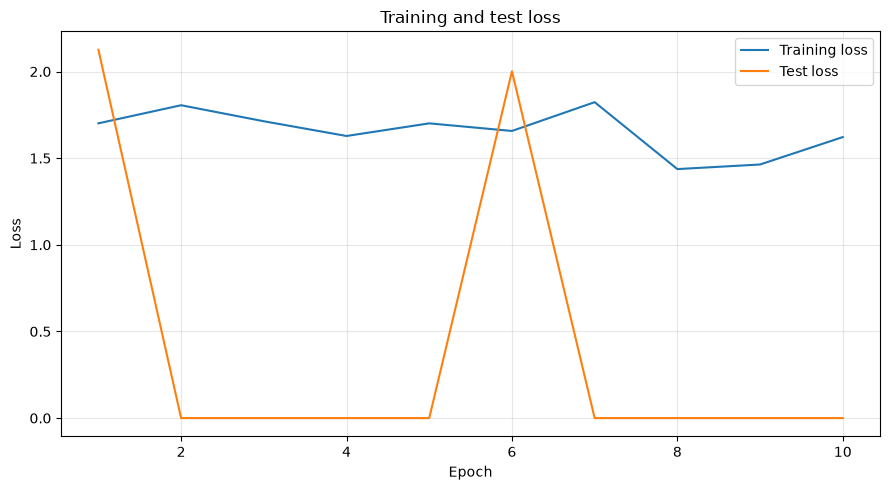

In [8]:
train_loss_values = np.asarray(train_losses, dtype=float).reshape(-1)
test_loss_values = np.asarray(test_losses, dtype=float).reshape(-1)

if train_loss_values.size == 0:
    raise ValueError("No training losses were returned; cannot plot the learning curve")

plt.figure(figsize=(9, 5))
plt.plot(
    np.arange(1, train_loss_values.size + 1),
    train_loss_values,
    label="Training loss",
)
if test_loss_values.size:
    plt.plot(
        np.arange(1, test_loss_values.size + 1),
        test_loss_values,
        label="Test loss",
    )
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and test loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

In [9]:
test_loss_values

array([2.12562984, 0.        , 0.        , 0.        , 0.        ,
       2.00122845, 0.        , 0.        , 0.        , 0.        ])

## Compare the fine-tuned model with the default and ground truth

The default predictions above were generated before fine-tuning. This visualization compares those predictions with the fine-tuned model and test ground truth.

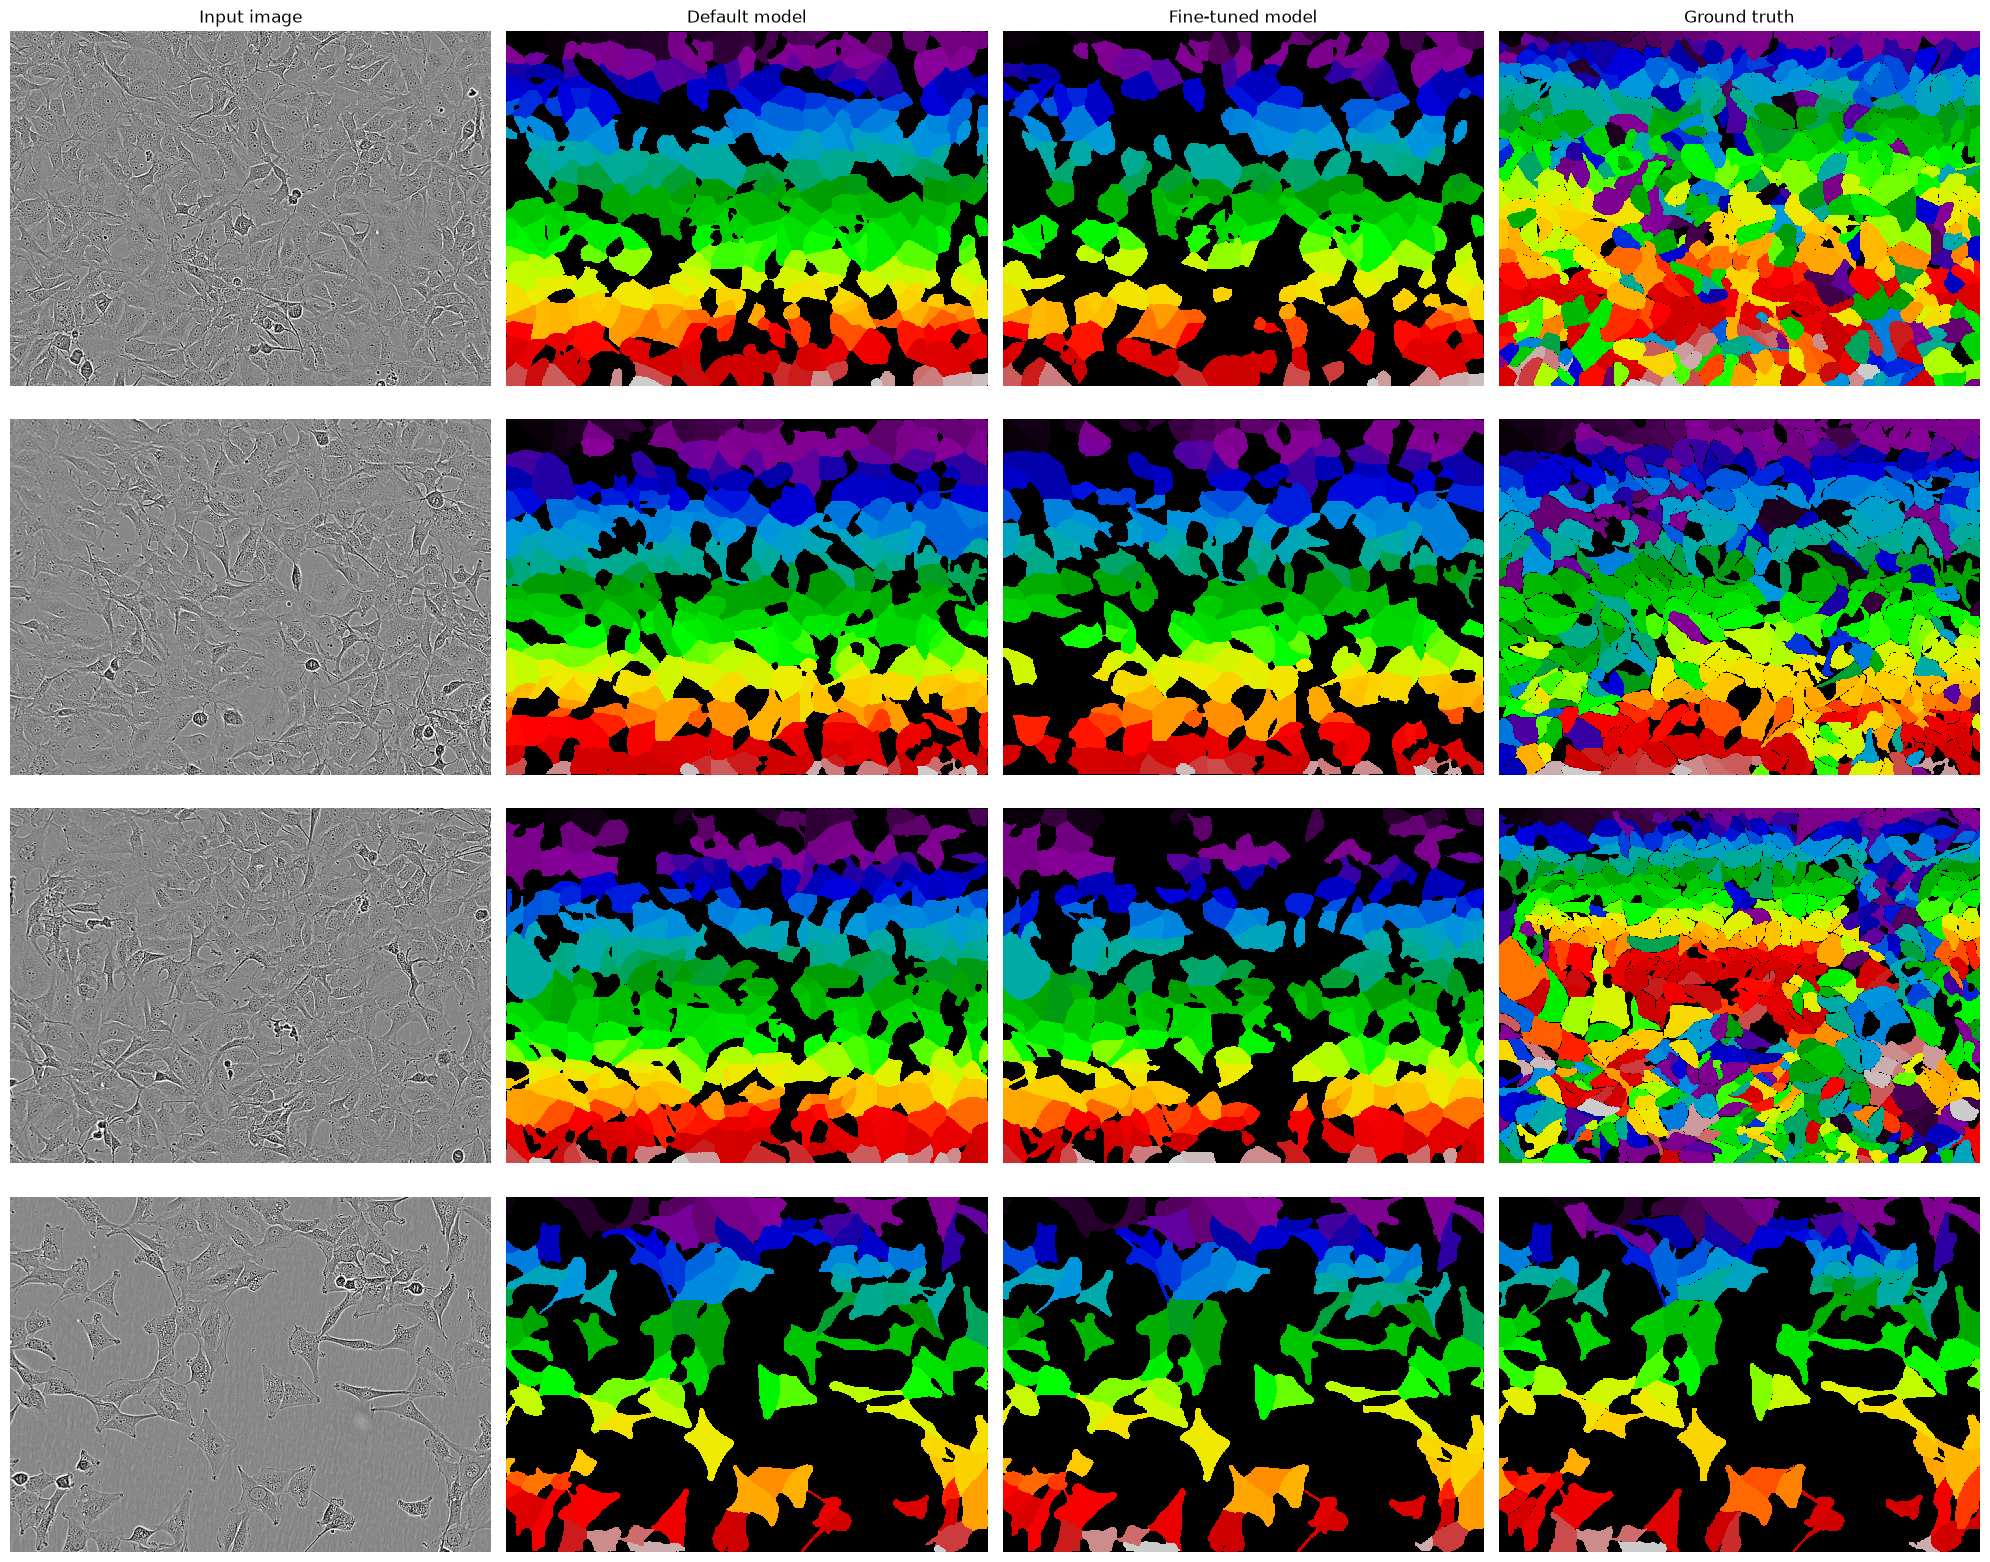

In [9]:
fine_tuned_test_predictions = [
    trained_model.eval(image)[0] for image in test_data[:n_preview]
]

fig, axes = plt.subplots(n_preview, 4, figsize=(20, 4 * n_preview), squeeze=False)
titles = ("Input image", "Default model", "Fine-tuned model", "Ground truth")
for row, (image, default_mask, fine_tuned_mask, true_mask, image_path) in enumerate(
    zip(
        test_data[:n_preview],
        default_test_predictions,
        fine_tuned_test_predictions,
        test_labels[:n_preview],
        test_image_paths[:n_preview],
    )
):
    axes[row, 0].imshow(to_display(image), cmap="gray")
    axes[row, 1].imshow(default_mask, cmap="nipy_spectral", interpolation="nearest")
    axes[row, 2].imshow(fine_tuned_mask, cmap="nipy_spectral", interpolation="nearest")
    axes[row, 3].imshow(true_mask, cmap="nipy_spectral", interpolation="nearest")
    axes[row, 0].set_ylabel(Path(image_path).name)
    for column in range(4):
        axes[row, column].set_axis_off()
        if row == 0:
            axes[row, column].set_title(titles[column])

plt.tight_layout()